# 01 - EDA

QRT Challenge Data 167, Asset Allocation Performance Forecasting.

Pas de modèle ici. Le but est de comprendre la structure des données avant de choisir le protocole de validation.

Notations : `RET_1` est le rendement du jour t (le plus récent), `RET_20` le plus ancien, `target` le rendement en t+1.
La métrique est l'accuracy sur le signe de `target`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

SEED = 42
rng = np.random.default_rng(SEED)

# le notebook peut être lancé depuis la racine du projet ou depuis notebooks/
DATA = next(p for p in [Path('data'), Path('../data')] if (p / 'X_train.csv').exists())

plt.rcParams.update({'figure.figsize': (9, 3.6), 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True,
                     'grid.alpha': .25, 'font.size': 10})
BLUE, ORANGE, GREY = '#2a6fdb', '#d9822b', '#8a8f98'

X = pd.read_csv(DATA / 'X_train.csv', index_col='ROW_ID')
y = pd.read_csv(DATA / 'y_train.csv', index_col='ROW_ID')['target']
Xt = pd.read_csv(DATA / 'X_test.csv', index_col='ROW_ID')
assert X.index.equals(y.index)

RET = [f'RET_{i}' for i in range(1, 21)]
d = X.assign(target=y, up=(y > 0).astype(int))
X.shape, Xt.shape

((527073, 44), (31870, 44))

## 1. Structure du panel

In [2]:
for name, df in [('train', X), ('test', Xt)]:
    n = df.groupby('TS').size()
    print(f"{name}: {df.TS.nunique()} dates ({df.TS.min()} -> {df.TS.max()}), "
          f"{df.ALLOCATION.nunique()} allocations, lignes/date {n.min()}-{n.max()} (med {int(n.median())}), "
          f"doublons (TS, ALLOCATION) = {df.duplicated(['TS', 'ALLOCATION']).sum()}")

print('dates communes train/test :', len(set(X.TS) & set(Xt.TS)))
print('allocations par groupe :', X.groupby('GROUP').ALLOCATION.nunique().to_dict())
X.isna().mean().sort_values(ascending=False).head(4).round(3)

train: 2522 dates (DATE_0001 -> DATE_2522), 278 allocations, lignes/date 65-276 (med 276), doublons (TS, ALLOCATION) = 0
test: 120 dates (DATE_2523 -> DATE_2642), 278 allocations, lignes/date 70-278 (med 278), doublons (TS, ALLOCATION) = 0


dates communes train/test : 0
allocations par groupe : {1: 70, 2: 70, 3: 70, 4: 68}


SIGNED_VOLUME_1          0.735
SIGNED_VOLUME_20         0.016
MEDIAN_DAILY_TURNOVER    0.007
SIGNED_VOLUME_19         0.006
dtype: float64

Train et test n'ont aucune date en commun mais partagent les 278 allocations.
L'univers varie beaucoup d'une date à l'autre (65 à 276 allocations).
`SIGNED_VOLUME_1` est manquant à 73 %, tout le reste est quasi complet. On y revient en section 4.

## 2. Cible

P(target > 0) = 0.5072, zéros exacts : 0, kurtosis : 7.7
{0.001: -0.0159, 0.01: -0.0086, 0.5: 0.0, 0.99: 0.0084, 0.999: 0.016}
       base_rate     vol       n
GROUP                           
1         0.5005  0.0031  100170
2         0.5098  0.0031  134928
3         0.5099  0.0035  168913
4         0.5060  0.0025  123062


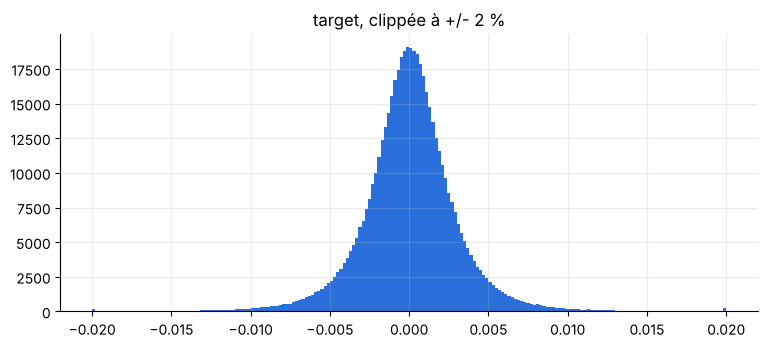

In [3]:
print(f"P(target > 0) = {d.up.mean():.4f}, zéros exacts : {(y == 0).sum()}, kurtosis : {y.kurt():.1f}")
print(y.quantile([.001, .01, .5, .99, .999]).round(4).to_dict())
print(d.groupby('GROUP').agg(base_rate=('up', 'mean'), vol=('target', 'std'), n=('up', 'size')).round(4))

plt.hist(y.clip(-0.02, 0.02), bins=200, color=BLUE)
plt.title('target, clippée à +/- 2 %')
plt.show()

Base rate de 50,7 % : c'est ce que fait un modèle qui prédit toujours 1, donc le plancher.
Queues épaisses (kurtosis proche de 8). Si on entraîne en régression avec une MSE, quelques journées extrêmes pèseront lourd.
Pas de zéro exact, la convention sign(0) = 0 ne pose pas de problème.

## 3. Quels lags portent de l'information ?

Corrélation de la cible avec chaque `RET_k`, puis quelques règles sans paramètre.
Ces règles n'estiment rien, donc leur accuracy sur le train ne peut pas être gonflée par du surapprentissage.

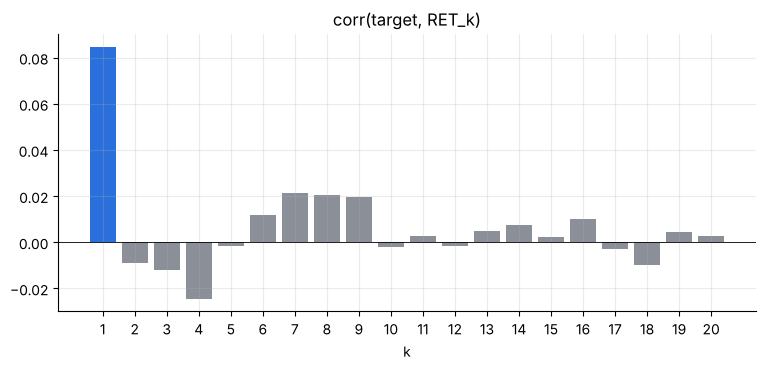

toujours 1                 0.5072
signe RET_1                0.5189
signe moyenne RET_1..5     0.5056
signe moyenne RET_1..20    0.5082
dtype: float64

In [4]:
lag_corr = pd.Series({k: d.target.corr(d[f'RET_{k}']) for k in range(1, 21)})

plt.bar(lag_corr.index, lag_corr.values, color=[BLUE if k == 1 else GREY for k in lag_corr.index])
plt.axhline(0, color='k', lw=.6)
plt.xticks(range(1, 21))
plt.title('corr(target, RET_k)')
plt.xlabel('k')
plt.show()

rules = {
    'toujours 1': np.ones(len(d), dtype=bool),
    'signe RET_1': d.RET_1 > 0,
    'signe moyenne RET_1..5': d[RET[:5]].mean(axis=1) > 0,
    'signe moyenne RET_1..20': d[RET].mean(axis=1) > 0,
}
pd.Series({k: (v == (d.up == 1)).mean() for k, v in rules.items()}).round(4)

On sépare ensuite ce qui est commun à toutes les allocations d'une même date et ce qui est propre à chaque allocation.

In [5]:
date_mean = lambda c: d.groupby('TS')[c].transform('mean')

share_date = date_mean('target').var() / y.var()
corr_idio = (d.target - date_mean('target')).corr(d.RET_1 - date_mean('RET_1'))
corr_common = d.groupby('TS')[['target', 'RET_1']].mean().corr().iloc[0, 1]
print(f"variance de la cible expliquée par la date : {share_date:.3f}")
print(f"corr écarts à la date : {corr_idio:.4f}, corr moyennes par date : {corr_common:.4f}")

d.groupby('GROUP').apply(lambda g: pd.Series({
    'corr(target, RET_1)': g.target.corr(g.RET_1),
    'acc signe RET_1': ((g.RET_1 > 0) == (g.up == 1)).mean()})).round(4)

variance de la cible expliquée par la date : 0.066
corr écarts à la date : 0.0807, corr moyennes par date : 0.1472


,"corr(target, RET_1)",acc signe RET_1
GROUP,,
1,0.1179,0.5231
2,0.0830,0.5219
3,0.0754,0.5146
4,0.0733,0.5182


Presque tout se joue sur le lag 1 : corr(target, RET_1) = 0,085, les autres lags sont autour de 0.
Prédire le signe du rendement de la veille donne 51,9 % sans rien estimer. Pour comparaison, le benchmark LightGBM
fait 52,2 % en CV et 50,79 % en public.

L'effet tient encore une fois l'effet date retiré (0,081). C'est donc surtout une propriété des allocations, pas un simple
momentum de marché. Il est plus marqué dans le groupe 1.

Une autocorrélation positive d'ordre 1 sur des rendements de portefeuille n'a rien d'étonnant (prix non synchrones,
exécution étalée sur plusieurs séances). Mais ce genre d'effet s'érode, donc il faut vérifier s'il tient sur la période test (section 7).

## 4. Volumes, turnover, NaN de SIGNED_VOLUME_1

In [6]:
nan_by_date = X.SIGNED_VOLUME_1.isna().groupby(X.TS).mean()
print('part de NaN par date, train :', nan_by_date.round(1).value_counts().to_dict())
print('part de NaN par date, test  :', Xt.SIGNED_VOLUME_1.isna().groupby(Xt.TS).mean().round(1).value_counts().to_dict())

d['sv1_day'] = d.TS.map(nan_by_date < 0.5)
print(d.groupby('sv1_day').agg(base_rate=('up', 'mean'), n=('up', 'size')).round(4))

print({c: round(d.target.corr(d[c]), 4) for c in ['SIGNED_VOLUME_1', 'SIGNED_VOLUME_2', 'MEDIAN_DAILY_TURNOVER']})
d[['SIGNED_VOLUME_2', 'MEDIAN_DAILY_TURNOVER']].describe().round(3)

part de NaN par date, train : {0.9: 2020, 0.0: 502}
part de NaN par date, test  : {0.9: 98, 0.0: 22}
         base_rate       n
sv1_day                   
False       0.5040  424550
True        0.5205  102523
{'SIGNED_VOLUME_1': np.float64(0.0043), 'SIGNED_VOLUME_2': np.float64(-0.0046), 'MEDIAN_DAILY_TURNOVER': np.float64(0.0134)}


,SIGNED_VOLUME_2,MEDIAN_DAILY_TURNOVER
count,527073.000,523435.000
mean,0.259,0.091
std,1.584,0.236
min,-115.229,0.000
25%,-0.744,0.002
50%,0.636,0.016
75%,1.099,0.044
max,78.657,1.560


Les NaN de `SIGNED_VOLUME_1` se répartissent par date : soit la date est quasi complète, soit elle est vide à 90 %.
Environ une date sur cinq est complète. La section 6 montre qu'il s'agit d'un motif hebdomadaire, ce qui donne un indicateur
du jour de la semaine. Ces dates ont un base rate plus élevé (52,1 % contre 50,4 %).

Volume et turnover sont décorrélés de la cible en linéaire. S'ils servent à quelque chose, ce sera plutôt en interaction
(par exemple pour moduler l'autocorrélation). Le volume a des valeurs extrêmes (-115 / +79), il faudra le passer en rangs ou le winsoriser.

## 5. Différences entre allocations

Certaines allocations sont-elles durablement gagnantes ou perdantes ? On estime le base rate de chaque allocation sur
une moitié des dates, tirée au hasard, et on regarde s'il se retrouve sur l'autre moitié.

In [7]:
g = d.groupby('ALLOCATION').up.agg(['mean', 'size'])
print(f"écart-type des base rates : {g['mean'].std():.4f} (attendu sous H0 : {np.sqrt(.25 / g['size']).mean():.4f}), "
      f"min {g['mean'].min():.3f}, max {g['mean'].max():.3f}")

dates = d.TS.unique()
corr_halves, acc_oos = [], []
for _ in range(20):
    half = d.TS.isin(rng.choice(dates, len(dates) // 2, replace=False))
    a = d[half].groupby('ALLOCATION').up.mean()
    b = d[~half].groupby('ALLOCATION').up.mean()
    corr_halves.append(a.corr(b))
    acc_oos.append(((d.ALLOCATION[~half].map(a) > .5) == (d.up[~half] == 1)).mean())

print(f"corrélation entre moitiés : {np.mean(corr_halves):.3f}")
print(f"accuracy hors échantillon, règle 'majorité de l'allocation' : {np.mean(acc_oos):.4f} +/- {np.std(acc_oos):.4f}")

écart-type des base rates : 0.0274 (attendu sous H0 : 0.0123), min 0.385, max 0.659


corrélation entre moitiés : 0.593
accuracy hors échantillon, règle 'majorité de l'allocation' : 0.5111 +/- 0.0010


La dispersion entre allocations fait à peu près le double de ce que donnerait le hasard, et elle se retrouve d'une moitié à l'autre
(corrélation de 0,59). La règle seule fait 51,1 % hors échantillon.

Deux réserves. Les moitiés sont tirées au hasard dans le temps : si le style d'une allocation dérive, la persistance est surestimée.
Et toute feature construite à partir de l'identité de l'allocation (target encoding) devra être calculée à l'intérieur des plis
d'entraînement uniquement. C'est la source de fuite la plus probable du projet.

## 6. L'ordre des dates est-il chronologique ?

La consigne prévient qu'il n'y a pas de garantie de continuité. On teste deux choses.

1. La volatilité se regroupe dans le temps. Si les labels étaient chronologiques, la vol moyenne d'une date ressemblerait à celle de la date suivante.
2. Les fenêtres se recouvrent : si b est le lendemain de a, `RET_2` de b doit ressembler à `RET_1` de a. On compare les coupes
   transversales de toutes les paires de dates (train et test réunis).

In [8]:
ts_num = d.TS.str[5:].astype(int)
vol = d.groupby(ts_num).RET_1.apply(lambda s: s.abs().mean()).sort_index()
shuffled = pd.Series(vol.sample(frac=1, random_state=SEED).values)
print(f"autocorr lag 1 de la vol par date, ordre des labels : {vol.autocorr(1):.3f}, ordre aléatoire : {shuffled.autocorr(1):.3f}")

autocorr lag 1 de la vol par date, ordre des labels : 0.030, ordre aléatoire : 0.000


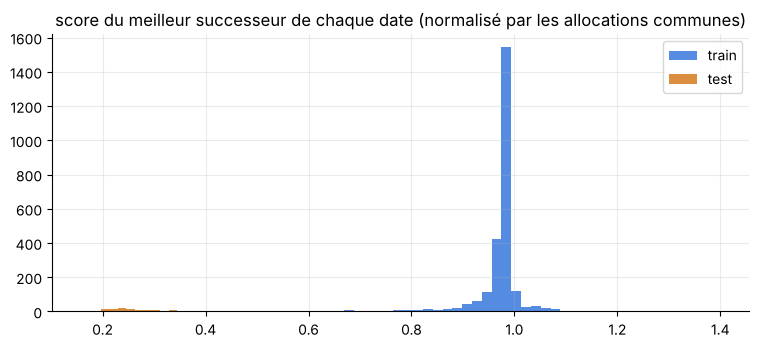

dates train avec un successeur net (score > 0.5) : 100.0%
dates test avec un successeur net : 0 / 120
dates test qui sont le successeur net d'une autre date : 0


In [9]:
D = pd.concat([X, Xt])
all_dates = sorted(D.TS.unique())
allocs = sorted(D.ALLOCATION.unique())
# cube[k, date, allocation] = RET_{k+1}
cube = np.stack([D.pivot(index='TS', columns='ALLOCATION', values=c)
                   .reindex(index=all_dates, columns=allocs).to_numpy() for c in RET])

def standardize(M):
    # centre-réduit chaque coupe transversale, NaN -> 0
    M = M - np.nanmean(M, -1, keepdims=True)
    return np.nan_to_num(M / np.sqrt(np.nanmean(M ** 2, -1, keepdims=True)))

Z = standardize(cube)
L = 10
# S[a, b] : corrélation moyenne entre RET_k(a) et RET_{k+1}(b), k = 1..10. Élevé si b est le lendemain de a.
# On divise par le nombre d'allocations présentes les deux jours (et pas par 278) :
# sinon le score est dilué quand l'univers est plus petit (140 ou 206 allocations au lieu de 276).
present = (~np.isnan(cube[:L + 1])).all(0).astype(float)      # date x allocation
common = present @ present.T                                  # nb d'allocations communes à a et b
S = sum(Z[k] @ Z[k + 1].T for k in range(L)) / (L * np.maximum(common, 1))
S[common < 30] = -np.inf                                      # trop peu d'allocations communes pour conclure
np.fill_diagonal(S, -np.inf)
succ, score = S.argmax(1), S.max(1)
score[~np.isfinite(score)] = np.nan                         # dates sans aucun voisin comparable
is_test = np.array([t >= 'DATE_2523' for t in all_dates])

ok = ~np.isnan(score)
plt.hist(score[~is_test & ok], bins=60, color=BLUE, alpha=.8, label='train')
plt.hist(score[is_test & ok], bins=20, color=ORANGE, alpha=.9, label='test')
plt.title('score du meilleur successeur de chaque date (normalisé par les allocations communes)')
plt.legend()
plt.show()

print(f"dates train avec un successeur net (score > 0.5) : {(score[~is_test] > .5).mean():.1%}")
print(f"dates test avec un successeur net : {(score[is_test] > .5).sum()} / {is_test.sum()}")
print(f"dates test qui sont le successeur net d'une autre date : {np.isin(np.where(is_test)[0], succ[score > .5]).sum()}")

In [10]:
# sur le train, est-ce que RET_1 du lendemain donne le signe de la cible ?
P1 = cube[0]
Ptgt = d.pivot(index='TS', columns='ALLOCATION', values='target').reindex(index=all_dates, columns=allocs).to_numpy()
agree = []
for a in np.where(~is_test & (score > .5))[0]:
    m = ~np.isnan(Ptgt[a]) & ~np.isnan(P1[succ[a]])
    agree.append(((Ptgt[a][m] > 0) == (P1[succ[a]][m] > 0)).mean())
print(f"accord de signe target(a) / RET_1(lendemain de a) : {np.mean(agree):.3f}")

# chaînes de dates consécutives (liens réciproques uniquement)
link = {a: succ[a] for a in range(len(all_dates)) if score[a] > .5 and S[:, succ[a]].argmax() == a}
chains = []
for h in set(link) - set(link.values()):
    c = [h]
    while c[-1] in link and len(c) <= len(all_dates):
        c.append(link[c[-1]])
    chains.append(c)
chains.sort(key=len, reverse=True)
print(f"{len(chains)} chaînes, les plus longues : {[len(c) for c in chains[:6]]}")

sv1_full = D.SIGNED_VOLUME_1.notna().groupby(D.TS).mean().reindex(all_dates).to_numpy() > .5
print('SV_1 renseigné (F) le long de la plus longue chaîne :')
print(''.join('F' if sv1_full[i] else '.' for i in chains[0][:100]))

accord de signe target(a) / RET_1(lendemain de a) : 0.883
4 chaînes, les plus longues : [1780, 348, 256, 130]
SV_1 renseigné (F) le long de la plus longue chaîne :
F....F....F....F........F....F....F....F...F....F....F....F....F....F....F....F.......F....F....F...


Les labels de dates sont mélangés : la vol n'a aucune persistance dans l'ordre des labels.
Un split sur « les dernières dates » n'aurait donc aucun sens temporel.

En revanche, les fenêtres se recouvrent d'un jour à l'autre, et toutes les dates du train ont un lendemain identifiable une fois
le score normalisé par le nombre d'allocations communes. Sans cette normalisation, les dates à petit univers (65 à 206 allocations)
avaient un score artificiellement bas, ce qui donnait plusieurs pics sur l'histogramme. Le recouvrement n'est pas parfait,
probablement parce que la fenêtre est un backtest des poids du jour, qui bougent avec le turnover.

Le train se remet presque entièrement en ordre : 4 chaînes seulement, dont une de 1 780 dates. On dispose donc en pratique
de la chronologie du train. Sur ces chaînes, `RET_1` du lendemain donne le signe de la cible dans 88 % des cas.

Le test est isolé : aucune date test n'a de voisine, ni dans le test ni dans le train. Ce recouvrement n'est donc pas
exploitable sur le test, et ce n'est pas lui qui explique les 0,81 du classement public.

Le motif de `SIGNED_VOLUME_1` revient toutes les cinq dates le long des chaînes (avec quelques trous, sans doute des jours fériés) :
c'est bien un jour de la semaine.

Conséquence pour la validation : une date de validation et sa voisine dans le train partagent presque la même information
de marché. Comme la chronologie du train est connue, on peut valider par blocs de dates consécutives, avec une purge aux frontières.

## 7. Dérive entre train et test

Le benchmark perd 1,4 point entre sa CV et le public. On cherche un changement visible sans la cible test, en particulier
dans l'autocorrélation à l'intérieur des fenêtres, puisque c'est elle qui porte le signal.

In [11]:
def window_autocorr(df):
    return np.mean([df[f'RET_{k}'].corr(df[f'RET_{k+1}']) for k in range(1, 20)])

pd.DataFrame({name: {'autocorr intra-fenêtre': window_autocorr(df),
                     'corr(RET_1, RET_2)': df.RET_1.corr(df.RET_2),
                     'std RET_1': df.RET_1.std(),
                     'P(RET_1 > 0)': (df.RET_1 > 0).mean(),
                     'turnover médian': df.MEDIAN_DAILY_TURNOVER.median(),
                     'univers par date (med)': df.groupby('TS').size().median()}
              for name, df in [('train', X), ('test', Xt)]}).round(4)

,train,test
autocorr intra-fenêtre,0.0487,0.0324
"corr(RET_1, RET_2)",0.0679,0.0325
std RET_1,0.0030,0.0030
P(RET_1 > 0),0.5117,0.5152
turnover médian,0.0159,0.0150
univers par date (med),276.0000,278.0000


In [12]:
# la différence dépasse-t-elle la variabilité d'un échantillon de 120 dates ?
per_date = lambda df: df.groupby('TS').apply(window_autocorr)
ac_train, ac_test = per_date(X), per_date(Xt).mean()
boot = [ac_train.sample(120, random_state=s).mean() for s in range(500)]
print(f"test : {ac_test:.4f}, train (120 dates tirées 500 fois) : {np.mean(boot):.4f} "
      f"[{np.percentile(boot, 2.5):.4f}, {np.percentile(boot, 97.5):.4f}]")

test : 0.0231, train (120 dates tirées 500 fois) : 0.0359 [0.0261, 0.0453]


Les distributions marginales sont proches (vol, turnover, part de rendements positifs). L'autocorrélation, elle, est plus faible
sur le test : 0,023 contre 0,036 en moyenne par date, juste sous la borne basse de l'intervalle bootstrap (0,026).
C'est significatif sans être spectaculaire. Le test a aussi l'univers complet (278 allocations), ce qui fait penser à une période plus récente.

Hypothèse de travail : le signal d'autocorrélation est plus faible sur la période test, ce qui expliquerait une partie de l'écart
CV/public du benchmark. On le vérifiera au moment des soumissions.

## Bilan

- Plancher : 50,7 % (toujours 1).
- Signal principal : le lag 1, surtout idiosyncratique. Règle naïve à 51,9 % sur le train.
- Le style des allocations est persistant. Utile, mais à encoder uniquement dans les plis.
- Les NaN de SV_1 donnent un indicateur de jour de la semaine.
- Les dates sont mélangées, la chronologie se reconstruit par chaînes, le test est isolé. La CV se fera par blocs de dates consécutives, avec purge.
- L'autocorrélation est plus faible sur le test. Il faut s'attendre à un écart entre CV et public.